# **Load and understand the datasets**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving accounts.csv to accounts.csv
Saving channels.csv to channels.csv
Saving customers.csv to customers.csv
Saving service.csv to service.csv
Saving transactions.csv to transactions.csv


In [3]:
customers = pd.read_csv("customers.csv")
accounts = pd.read_csv("accounts.csv")
transactions = pd.read_csv("transactions.csv")
channels = pd.read_csv("channels.csv")
service = pd.read_csv("service.csv")

datasets = {
    "Customers": customers,
    "Accounts": accounts,
    "Transactions": transactions,
    "Channels": channels,
    "Service": service
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

Customers: 1200 rows, 4 columns
Accounts: 1641 rows, 4 columns
Transactions: 21997 rows, 6 columns
Channels: 1200 rows, 5 columns
Service: 1356 rows, 6 columns


**Display the first five records**

In [4]:
for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(name.upper())
    print("="*50)
    display(df.head())


CUSTOMERS


,customer_id,age_band,region,relationship_years
0,CUST00001,36-45,South,17
1,CUST00002,46-60,West,2
2,CUST00003,60+,Central,23
3,CUST00004,60+,West,10
4,CUST00005,26-35,West,4



ACCOUNTS


,account_id,customer_id,account_type,balance_band
0,ACC000001,CUST00001,Savings,100K-500K
1,ACC000002,CUST00002,Savings,100K-500K
2,ACC000003,CUST00003,Savings,500K+
3,ACC000004,CUST00004,Current,10K-50K
4,ACC000005,CUST00005,Current,50K-100K



TRANSACTIONS


,transaction_id,customer_id,account_id,transaction_date,amount,transaction_type
0,TXN00000001,CUST00001,ACC000001,2025-07-31,3793.10,Transfer
1,TXN00000002,CUST00001,ACC000001,2025-05-01,4284.16,Transfer
2,TXN00000003,CUST00001,ACC000001,2025-07-03,1604.08,Transfer
3,TXN00000004,CUST00001,ACC000001,2025-05-18,5664.84,Debit
4,TXN00000005,CUST00001,ACC000001,2025-10-12,1740.30,Debit



CHANNELS


,customer_id,branch_visits,atm_usage,mobile_usage,internet_usage
0,CUST00001,2.0,6.0,10.0,8.0
1,CUST00002,1.0,5.0,9.0,8.0
2,CUST00003,5.0,9.0,12.0,5.0
3,CUST00004,2.0,4.0,8.0,4.0
4,CUST00005,3.0,7.0,5.0,7.0



SERVICE


,service_id,customer_id,request_type,complaint_flag,resolution,service_date
0,SRV0000001,CUST00001,Loan Query,No,Resolved,2025-12-10
1,SRV0000002,CUST00002,Account Update,No,Resolved,2025-06-14
2,SRV0000003,CUST00003,Card Issue,Yes,Resolved,2025-03-11
3,SRV0000004,CUST00004,Loan Query,Yes,Resolved,2025-06-17
4,SRV0000005,CUST00004,Transaction Dispute,No,Resolved,2025-04-13


In [5]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Columns:", df.columns.tolist())
    df.info()


--- Customers ---
Columns: ['customer_id', 'age_band', 'region', 'relationship_years']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   customer_id         1200 non-null   object
 1   age_band            1200 non-null   object
 2   region              1200 non-null   object
 3   relationship_years  1200 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 37.6+ KB

--- Accounts ---
Columns: ['account_id', 'customer_id', 'account_type', 'balance_band']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1641 entries, 0 to 1640
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   account_id    1641 non-null   object
 1   customer_id   1641 non-null   object
 2   account_type  1641 non-null   object
 3   balance_band  1641 non-null   object
dtypes: object(4)
me

**Generate descriptive statistics**

In [6]:
for name, df in datasets.items():
    print(f"\n--- {name}: Descriptive Statistics ---")
    display(df.describe(include="all").T)


--- Customers: Descriptive Statistics ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,1200,1200,CUST01184,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_band,1200,5,26-35,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1200,5,South,276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship_years,1200.0,NaN,NaN,NaN,13.311667,7.307007,1.0,7.0,14.0,20.0,25.0



--- Accounts: Descriptive Statistics ---


,count,unique,top,freq
account_id,1641,1641,ACC001641,1
customer_id,1641,1200,CUST00174,3
account_type,1641,7,Savings,895
balance_band,1641,5,10K-50K,507



--- Transactions: Descriptive Statistics ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,21997,21823,TXN00017615,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,21997,1200,CUST00414,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_id,21997,1640,ACC000582,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,21997,365,2025-01-29,87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,21997.0,NaN,NaN,NaN,3525.165299,9576.939473,24.65,974.44,1959.86,4002.63,1015168.8
transaction_type,21997,5,Debit,7523,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Channels: Descriptive Statistics ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,1200,1200,CUST01184,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
branch_visits,1158.0,NaN,NaN,NaN,2.202936,1.479129,0.0,1.0,2.0,3.0,9.0
atm_usage,1158.0,NaN,NaN,NaN,4.955095,2.169097,0.0,3.0,5.0,6.0,14.0
mobile_usage,1158.0,NaN,NaN,NaN,10.837651,3.337469,2.0,8.0,11.0,13.0,22.0
internet_usage,1158.0,NaN,NaN,NaN,6.97323,2.62034,0.0,5.0,7.0,9.0,18.0



--- Service: Descriptive Statistics ---


,count,unique,top,freq
service_id,1356,1356,SRV0001356,1
customer_id,1356,859,CUST00025,4
request_type,1356,6,Transaction Dispute,236
complaint_flag,1262,2,No,889
resolution,1323,3,Resolved,1010
service_date,1356,361,2025-01-01,13


# **Check data quality**

**Check missing values**

In [7]:
for name, df in datasets.items():
    print(f"\n--- Missing Values: {name} ---")

    missing_report = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": (
            df.isnull().mean() * 100
        ).round(2)
    })

    display(missing_report)


--- Missing Values: Customers ---


,Missing Count,Missing Percentage
customer_id,0,0.0
age_band,0,0.0
region,0,0.0
relationship_years,0,0.0



--- Missing Values: Accounts ---


,Missing Count,Missing Percentage
account_id,0,0.0
customer_id,0,0.0
account_type,0,0.0
balance_band,0,0.0



--- Missing Values: Transactions ---


,Missing Count,Missing Percentage
transaction_id,0,0.0
customer_id,0,0.0
account_id,0,0.0
transaction_date,0,0.0
amount,0,0.0
transaction_type,0,0.0



--- Missing Values: Channels ---


,Missing Count,Missing Percentage
customer_id,0,0.0
branch_visits,42,3.5
atm_usage,42,3.5
mobile_usage,42,3.5
internet_usage,42,3.5



--- Missing Values: Service ---


,Missing Count,Missing Percentage
service_id,0,0.00
customer_id,0,0.00
request_type,0,0.00
complaint_flag,94,6.93
resolution,33,2.43
service_date,0,0.00


**Check duplicate records**

In [8]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} exact duplicate rows")

Customers: 0 exact duplicate rows
Accounts: 0 exact duplicate rows
Transactions: 173 exact duplicate rows
Channels: 0 exact duplicate rows
Service: 0 exact duplicate rows


In [9]:
print("Duplicate transaction IDs:",
      transactions["transaction_id"].duplicated().sum())

display(
    transactions[transactions.duplicated(keep=False)]
    .sort_values("transaction_id")
    .head(10)
)

Duplicate transaction IDs: 174


,transaction_id,customer_id,account_id,transaction_date,amount,transaction_type
312,TXN00000313,CUST00019,ACC000028,2025-07-11,1717.86,Transfer
21921,TXN00000313,CUST00019,ACC000028,2025-07-11,1717.86,Transfer
634,TXN00000635,CUST00038,ACC000058,2025-09-16,3179.87,Debit
21833,TXN00000635,CUST00038,ACC000058,2025-09-16,3179.87,Debit
681,TXN00000682,CUST00041,ACC000061,2025-08-06,1065.40,Bill Payment
21838,TXN00000682,CUST00041,ACC000061,2025-08-06,1065.40,Bill Payment
21915,TXN00000999,CUST00058,ACC000087,2025-05-01,6520.45,Bill Payment
998,TXN00000999,CUST00058,ACC000087,2025-05-01,6520.45,Bill Payment
21941,TXN00001040,CUST00062,ACC000092,2025-07-22,725.04,Debit
1039,TXN00001040,CUST00062,ACC000092,2025-07-22,725.04,Debit


**Detect unusual transaction amounts**

In [10]:
print(transactions["amount"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
))

Q1 = transactions["amount"].quantile(0.25)
Q3 = transactions["amount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = max(0, Q1 - 1.5 * IQR)
upper_limit = Q3 + 1.5 * IQR

outliers = transactions[
    (transactions["amount"] < lower_limit) |
    (transactions["amount"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential outliers:", len(outliers))

display(outliers.head())

count    2.199700e+04
mean     3.525165e+03
std      9.576939e+03
min      2.465000e+01
25%      9.744400e+02
50%      1.959860e+03
75%      4.002630e+03
95%      1.112832e+04
99%      2.331891e+04
max      1.015169e+06
Name: amount, dtype: float64
Lower limit: 0
Upper limit: 8544.915
Potential outliers: 1768


,transaction_id,customer_id,account_id,transaction_date,amount,transaction_type
56,TXN00000057,CUST00005,ACC000005,2025-06-07,12719.29,Debit
62,TXN00000063,CUST00005,ACC000005,2025-07-23,9647.38,Debit
79,TXN00000080,CUST00006,ACC000006,2025-08-11,8758.66,Transfer
97,TXN00000098,CUST00007,ACC000009,2025-12-23,8792.32,Bill Payment
102,TXN00000103,CUST00007,ACC000009,2025-08-05,30701.35,Transfer


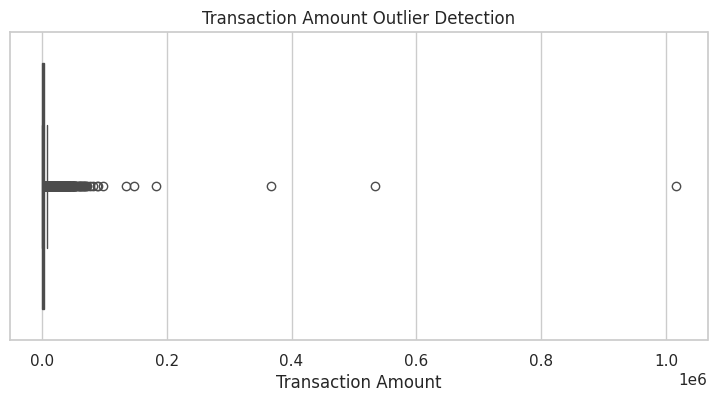

In [11]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=transactions["amount"])
plt.title("Transaction Amount Outlier Detection")
plt.xlabel("Transaction Amount")
plt.show()

# **Clean the datasets**

**Remove confirmed duplicate transactions**

In [12]:
transactions_clean = transactions.copy()

before = len(transactions_clean)

transactions_clean = transactions_clean.drop_duplicates(
    subset=["transaction_id"],
    keep="first"
)

after = len(transactions_clean)

print("Rows before cleaning:", before)
print("Rows after cleaning:", after)
print("Duplicate transactions removed:", before - after)

Rows before cleaning: 21997
Rows after cleaning: 21823
Duplicate transactions removed: 174


**Standardize account labels**

In [13]:
accounts_clean = accounts.copy()

accounts_clean["account_type"] = (
    accounts_clean["account_type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

label_mapping = {
    "savings": "Savings",
    "current": "Current",
    "fixed deposit": "Fixed Deposit",
    "salary": "Salary"
}

accounts_clean["account_type"] = (
    accounts_clean["account_type"]
    .map(label_mapping)
    .fillna(accounts_clean["account_type"].str.title())
)

print("Standardized account types:")
print(accounts_clean["account_type"].value_counts())

Standardized account types:
account_type
Savings          924
Current          272
Salary           225
Fixed Deposit    220
Name: count, dtype: int64


**Handle missing channel values**

In [14]:
channels_clean = channels.copy()

channel_columns = [
    "branch_visits",
    "atm_usage",
    "mobile_usage",
    "internet_usage"
]

for col in channel_columns:
    channels_clean[col + "_was_missing"] = (
        channels_clean[col].isnull().astype(int)
    )

    channels_clean[col] = channels_clean[col].fillna(
        channels_clean[col].median()
    )

print("Missing channel values after cleaning:")
display(channels_clean[channel_columns].isnull().sum())

Missing channel values after cleaning:


,0
branch_visits,0
atm_usage,0
mobile_usage,0
internet_usage,0


**Handle incomplete complaint records**

In [15]:
service_clean = service.copy()

service_clean["complaint_flag"] = (
    service_clean["complaint_flag"].fillna("Unknown")
)

service_clean["resolution"] = (
    service_clean["resolution"].fillna("Unknown")
)

print("Complaint status:")
display(service_clean["complaint_flag"].value_counts())

print("\nResolution status:")
display(service_clean["resolution"].value_counts())

Complaint status:


,count
complaint_flag,
No,889
Yes,373
Unknown,94



Resolution status:


,count
resolution,
Resolved,1010
Pending,215
Escalated,98
Unknown,33


**Convert dates into date format**

In [16]:
transactions_clean["transaction_date"] = pd.to_datetime(
    transactions_clean["transaction_date"],
    errors="coerce"
)

service_clean["service_date"] = pd.to_datetime(
    service_clean["service_date"],
    errors="coerce"
)

print(transactions_clean["transaction_date"].dtype)
print(service_clean["service_date"].dtype)

datetime64[ns]
datetime64[ns]


# **Combine datasets at the correct analysis level**

**Prepare transaction features**

In [17]:
transactions_clean["transaction_date"] = pd.to_datetime(
    transactions_clean["transaction_date"],
    errors="coerce"
)

transaction_features = (
    transactions_clean.groupby("customer_id")
    .agg(
        transaction_count=("transaction_id", "nunique"),
        total_transaction_amount=("amount", "sum"),
        average_transaction_amount=("amount", "mean"),
        last_transaction_date=("transaction_date", "max")
    )
    .reset_index()
)

display(transaction_features.head())

,customer_id,transaction_count,total_transaction_amount,average_transaction_amount,last_transaction_date
0,CUST00001,17,38691.18,2275.951765,2025-10-12
1,CUST00002,16,29347.55,1834.221875,2025-12-25
2,CUST00003,10,19452.99,1945.299000,2025-12-22
3,CUST00004,12,26822.23,2235.185833,2025-12-15
4,CUST00005,24,65388.56,2724.523333,2025-10-17


**Prepare account features**

In [18]:
account_features = (
    accounts_clean.groupby("customer_id")
    .agg(
        account_count=("account_id", "nunique"),
        account_type_count=("account_type", "nunique"),
        account_types=("account_type",
                       lambda x: ", ".join(sorted(x.dropna().unique())))
    )
    .reset_index()
)

display(account_features.head())

,customer_id,account_count,account_type_count,account_types
0,CUST00001,1,1,Savings
1,CUST00002,1,1,Savings
2,CUST00003,1,1,Savings
3,CUST00004,1,1,Current
4,CUST00005,1,1,Current


**Prepare service features**

In [19]:
service_clean["is_complaint"] = (
    service_clean["complaint_flag"] == "Yes"
).astype(int)

service_clean["is_unresolved"] = (
    service_clean["resolution"].isin(["Pending", "Escalated"])
).astype(int)

service_features = (
    service_clean.groupby("customer_id")
    .agg(
        service_request_count=("service_id", "nunique"),
        complaint_count=("is_complaint", "sum"),
        unresolved_request_count=("is_unresolved", "sum")
    )
    .reset_index()
)

display(service_features.head())

,customer_id,service_request_count,complaint_count,unresolved_request_count
0,CUST00001,1,0,0
1,CUST00002,1,0,0
2,CUST00003,1,1,0
3,CUST00004,2,1,0
4,CUST00005,1,0,0


**Merge into a customer-level dataset**

In [20]:
customer_data = customers.copy()

customer_data = customer_data.merge(
    account_features, on="customer_id", how="left"
)

customer_data = customer_data.merge(
    transaction_features, on="customer_id", how="left"
)

customer_data = customer_data.merge(
    channels_clean, on="customer_id", how="left"
)

customer_data = customer_data.merge(
    service_features, on="customer_id", how="left"
)

count_columns = [
    "account_count",
    "account_type_count",
    "transaction_count",
    "service_request_count",
    "complaint_count",
    "unresolved_request_count"
]

customer_data[count_columns] = (
    customer_data[count_columns].fillna(0)
)

print("Final customer-level dataset shape:", customer_data.shape)
print("Unique customers:", customer_data["customer_id"].nunique())

display(customer_data.head())

Final customer-level dataset shape: (1200, 22)
Unique customers: 1200


,customer_id,age_band,region,relationship_years,account_count,account_type_count,account_types,transaction_count,total_transaction_amount,average_transaction_amount,last_transaction_date,branch_visits,atm_usage,mobile_usage,internet_usage,branch_visits_was_missing,atm_usage_was_missing,mobile_usage_was_missing,internet_usage_was_missing,service_request_count,complaint_count,unresolved_request_count
0,CUST00001,36-45,South,17,1,1,Savings,17,38691.18,2275.951765,2025-10-12,2.0,6.0,10.0,8.0,0,0,0,0,1.0,0.0,0.0
1,CUST00002,46-60,West,2,1,1,Savings,16,29347.55,1834.221875,2025-12-25,1.0,5.0,9.0,8.0,0,0,0,0,1.0,0.0,0.0
2,CUST00003,60+,Central,23,1,1,Savings,10,19452.99,1945.299000,2025-12-22,5.0,9.0,12.0,5.0,0,0,0,0,1.0,1.0,0.0
3,CUST00004,60+,West,10,1,1,Current,12,26822.23,2235.185833,2025-12-15,2.0,4.0,8.0,4.0,0,0,0,0,2.0,1.0,0.0
4,CUST00005,26-35,West,4,1,1,Current,24,65388.56,2724.523333,2025-10-17,3.0,7.0,5.0,7.0,0,0,0,0,1.0,0.0,0.0


# **Exploratory Data Analysis (EDA)**

**Which channels are used most?**

,Total Usage
mobile_usage,13012.0
internet_usage,8369.0
atm_usage,5948.0
branch_visits,2635.0


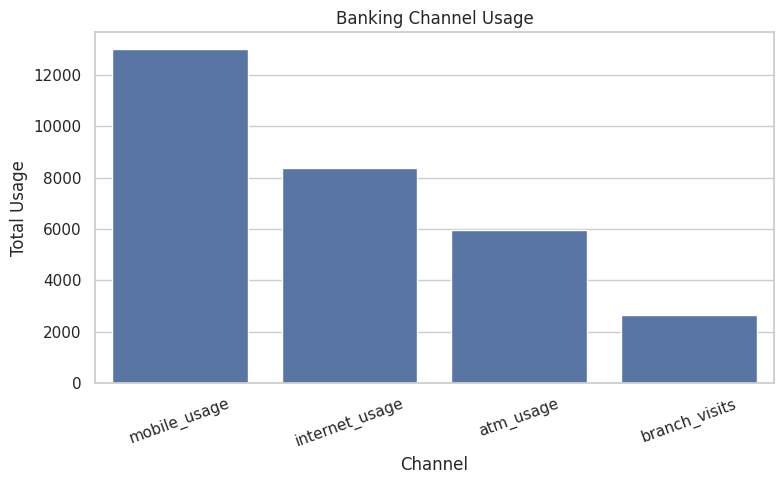

Most-used channel: mobile_usage


In [21]:
channel_totals = (
    channels_clean[channel_columns]
    .sum()
    .sort_values(ascending=False)
)

display(channel_totals.rename("Total Usage").to_frame())

plt.figure(figsize=(8, 5))
sns.barplot(
    x=channel_totals.index,
    y=channel_totals.values
)

plt.title("Banking Channel Usage")
plt.xlabel("Channel")
plt.ylabel("Total Usage")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Most-used channel:", channel_totals.idxmax())

**How does channel usage differ by age band?**

,branch_visits,atm_usage,mobile_usage,internet_usage
age_band,,,,
18-25,2.26,5.09,10.91,6.71
26-35,2.26,4.92,10.75,6.91
36-45,2.30,5.06,11.07,7.06
46-60,2.12,4.96,10.67,7.07
60+,1.92,4.68,10.83,7.09


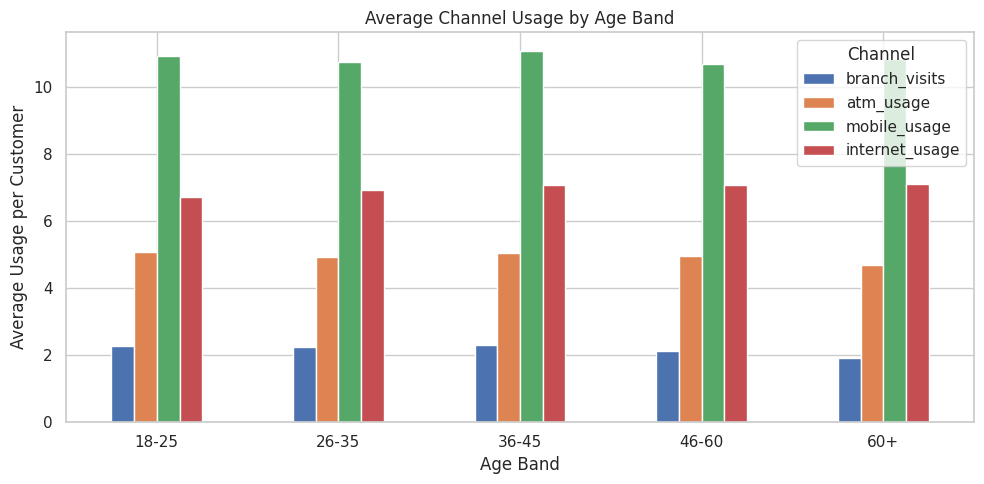

In [22]:
age_channel_data = customer_data[
    ["age_band"] + channel_columns
]

age_channel_summary = (
    age_channel_data.groupby("age_band")[channel_columns]
    .mean()
)

display(age_channel_summary.round(2))

age_channel_summary.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Channel Usage by Age Band")
plt.xlabel("Age Band")
plt.ylabel("Average Usage per Customer")
plt.xticks(rotation=0)
plt.legend(title="Channel")
plt.tight_layout()
plt.show()

**Which account types show lower activity?**

,account_type,transaction_count,unique_customers,median_transaction_amount,transactions_per_customer
1,Fixed Deposit,2710,207,1918.640,13.091787
0,Current,3624,258,2037.775,14.046512
2,Salary,3080,217,1966.680,14.193548
3,Savings,12409,779,1951.860,15.929397


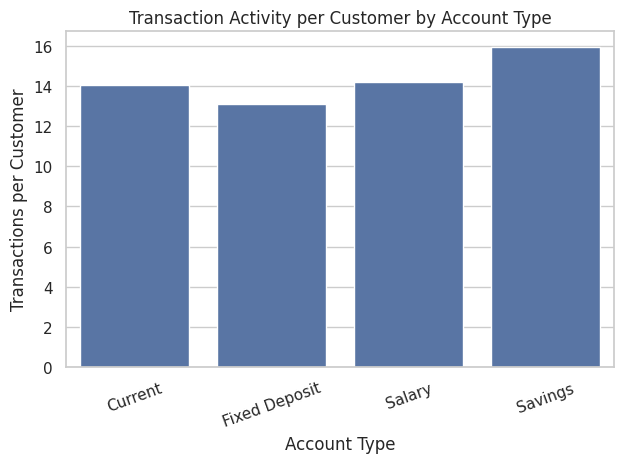

In [23]:
account_activity = transactions_clean.merge(
    accounts_clean[["account_id", "account_type"]],
    on="account_id",
    how="left"
)

account_activity_summary = (
    account_activity.groupby("account_type")
    .agg(
        transaction_count=("transaction_id", "nunique"),
        unique_customers=("customer_id", "nunique"),
        median_transaction_amount=("amount", "median")
    )
    .reset_index()
)

account_activity_summary["transactions_per_customer"] = (
    account_activity_summary["transaction_count"] /
    account_activity_summary["unique_customers"]
)

display(
    account_activity_summary.sort_values(
        "transactions_per_customer"
    )
)

sns.barplot(
    data=account_activity_summary,
    x="account_type",
    y="transactions_per_customer"
)

plt.title("Transaction Activity per Customer by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Transactions per Customer")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Identify declining account activity over time**

period,H1,H2,activity_change
account_type,,,
Salary,1530,1550,20
Savings,6193,6216,23
Current,1786,1838,52
Fixed Deposit,1301,1409,108


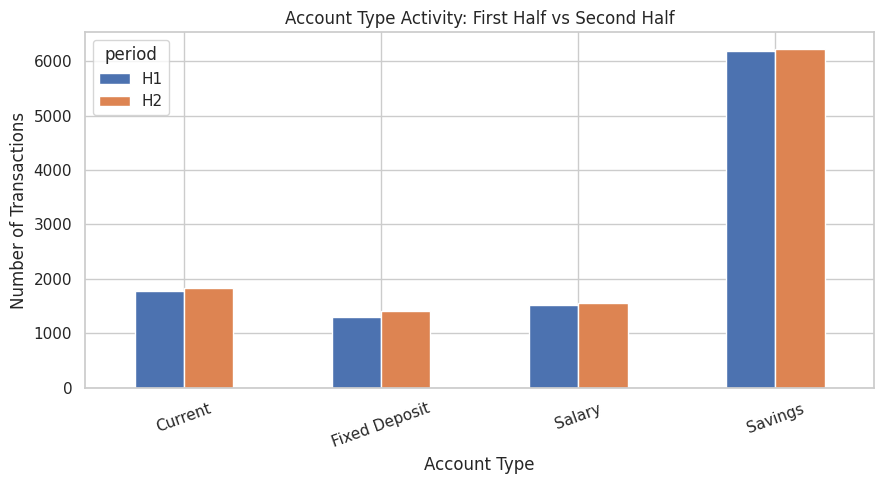

In [24]:
transactions_clean["transaction_date"] = pd.to_datetime(
    transactions_clean["transaction_date"],
    errors="coerce"
)

transactions_clean["period"] = np.where(
    transactions_clean["transaction_date"].dt.month <= 6,
    "H1",
    "H2"
)

account_period = (
    transactions_clean.merge(
        accounts_clean[["account_id", "account_type"]],
        on="account_id",
        how="left"
    )
    .groupby(["account_type", "period"])["transaction_id"]
    .nunique()
    .unstack(fill_value=0)
)

for period in ["H1", "H2"]:
    if period not in account_period.columns:
        account_period[period] = 0

account_period["activity_change"] = (
    account_period["H2"] - account_period["H1"]
)

display(account_period.sort_values("activity_change"))

account_period[["H1", "H2"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Account Type Activity: First Half vs Second Half")
plt.xlabel("Account Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Which regions generate more complaints?**

,region,service_records,complaints,complaint_rate_pct
3,South,307,98,31.92
4,West,327,82,25.08
1,East,241,69,28.63
2,North,242,65,26.86
0,Central,239,59,24.69


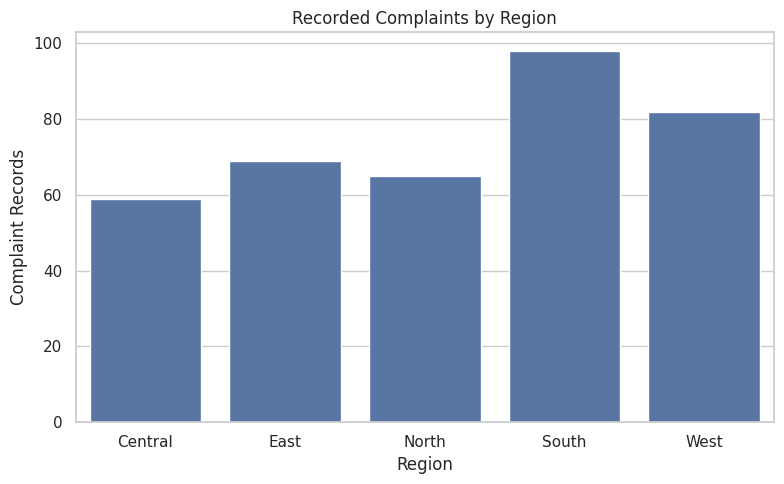

In [25]:
service_analysis = service_clean.merge(
    customers[["customer_id", "region"]],
    on="customer_id",
    how="left"
)

region_complaints = (
    service_analysis.groupby("region")
    .agg(
        service_records=("service_id", "nunique"),
        complaints=("is_complaint", "sum")
    )
    .reset_index()
)

region_complaints["complaint_rate_pct"] = (
    region_complaints["complaints"] /
    region_complaints["service_records"] * 100
).round(2)

display(region_complaints.sort_values("complaints", ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=region_complaints,
    x="region",
    y="complaints"
)

plt.title("Recorded Complaints by Region")
plt.xlabel("Region")
plt.ylabel("Complaint Records")
plt.tight_layout()
plt.show()

**How do balances differ by customer segment?**

balance_band,0-10K,100K-500K,10K-50K,500K+,50K-100K
age_band,,,,,
18-25,20.50,24.27,29.71,5.02,20.50
26-35,16.13,21.51,31.40,7.96,23.01
36-45,20.51,22.53,30.13,7.34,19.49
46-60,17.63,24.57,30.64,9.54,17.63
60+,16.33,20.92,33.16,10.71,18.88


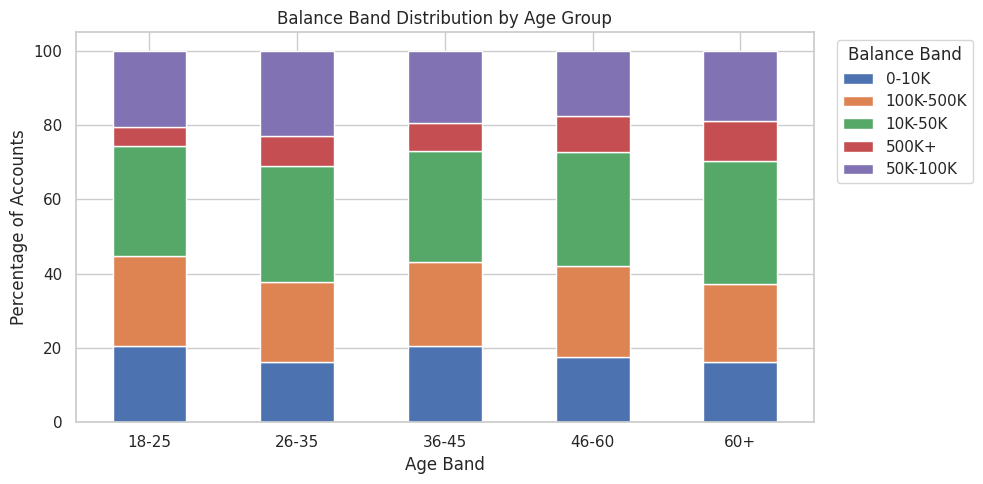

In [26]:
account_segments = accounts_clean.merge(
    customers[["customer_id", "age_band", "region"]],
    on="customer_id",
    how="left"
)

balance_by_age = pd.crosstab(
    account_segments["age_band"],
    account_segments["balance_band"],
    normalize="index"
) * 100

display(balance_by_age.round(2))

balance_by_age.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Balance Band Distribution by Age Group")
plt.xlabel("Age Band")
plt.ylabel("Percentage of Accounts")
plt.xticks(rotation=0)
plt.legend(title="Balance Band", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Which services drive repeated requests?**

,service_type,request_count
0,Transaction Dispute,236
1,Loan Query,229
2,Other,229
3,Card Issue,227
4,Digital Banking,224
5,Account Update,211


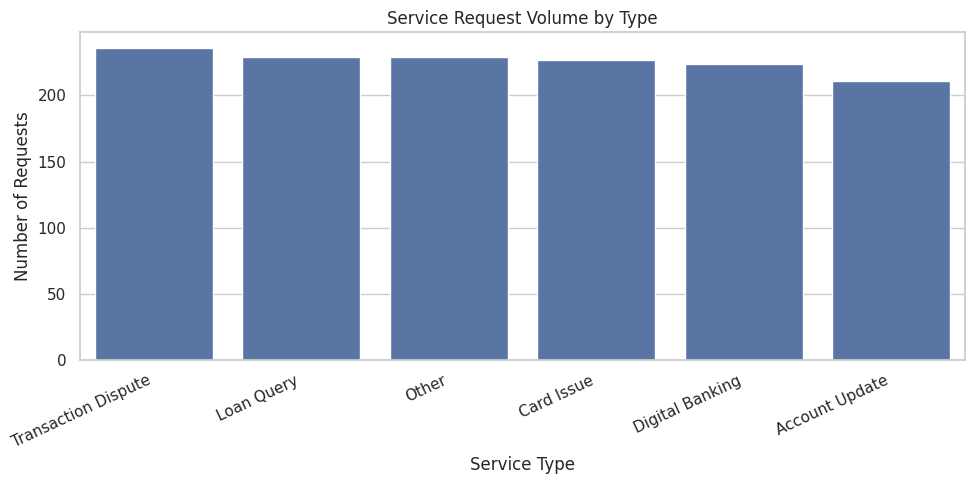

In [27]:
service_counts = (
    service_clean["request_type"]
    .value_counts()
    .rename_axis("service_type")
    .reset_index(name="request_count")
)

display(service_counts)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=service_counts,
    x="service_type",
    y="request_count"
)

plt.title("Service Request Volume by Type")
plt.xlabel("Service Type")
plt.ylabel("Number of Requests")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()



> To identify customers who repeatedly contact the bank, inspect customer-level request counts:



In [28]:
repeat_requests = (
    service_clean.groupby("customer_id")
    .size()
    .reset_index(name="request_count")
)

repeat_requests = repeat_requests[
    repeat_requests["request_count"] > 1
].sort_values("request_count", ascending=False)

display(repeat_requests.head(10))

,customer_id,request_count
50,CUST00068,4
759,CUST01054,4
767,CUST01065,4
768,CUST01067,4
750,CUST01045,4
666,CUST00924,4
85,CUST00119,4
166,CUST00233,4
692,CUST00961,4
650,CUST00901,4


# **Feature engineering**

**Create engagement features**

In [29]:
customer_data["channel_diversity"] = (
    customer_data[channel_columns].gt(0).sum(axis=1)
)

customer_data["total_channel_usage"] = (
    customer_data[channel_columns].sum(axis=1)
)

customer_data["engagement_segment"] = pd.cut(
    customer_data["transaction_count"],
    bins=[-1, 5, 15, 30, float("inf")],
    labels=["Low", "Moderate", "High", "Very High"]
)

customer_data["has_complaint"] = (
    customer_data["complaint_count"] > 0
).astype(int)

customer_data["has_unresolved_request"] = (
    customer_data["unresolved_request_count"] > 0
).astype(int)

display(customer_data.head())

,customer_id,age_band,region,relationship_years,account_count,account_type_count,account_types,transaction_count,total_transaction_amount,average_transaction_amount,last_transaction_date,branch_visits,atm_usage,mobile_usage,internet_usage,branch_visits_was_missing,atm_usage_was_missing,mobile_usage_was_missing,internet_usage_was_missing,service_request_count,complaint_count,unresolved_request_count,channel_diversity,total_channel_usage,engagement_segment,has_complaint,has_unresolved_request
0,CUST00001,36-45,South,17,1,1,Savings,17,38691.18,2275.951765,2025-10-12,2.0,6.0,10.0,8.0,0,0,0,0,1.0,0.0,0.0,4,26.0,High,0,0
1,CUST00002,46-60,West,2,1,1,Savings,16,29347.55,1834.221875,2025-12-25,1.0,5.0,9.0,8.0,0,0,0,0,1.0,0.0,0.0,4,23.0,High,0,0
2,CUST00003,60+,Central,23,1,1,Savings,10,19452.99,1945.299000,2025-12-22,5.0,9.0,12.0,5.0,0,0,0,0,1.0,1.0,0.0,4,31.0,Moderate,1,0
3,CUST00004,60+,West,10,1,1,Current,12,26822.23,2235.185833,2025-12-15,2.0,4.0,8.0,4.0,0,0,0,0,2.0,1.0,0.0,4,18.0,Moderate,1,0
4,CUST00005,26-35,West,4,1,1,Current,24,65388.56,2724.523333,2025-10-17,3.0,7.0,5.0,7.0,0,0,0,0,1.0,0.0,0.0,4,22.0,High,0,0


**Create recency and activity-change features**

In [30]:
transactions_clean["transaction_date"] = pd.to_datetime(
    transactions_clean["transaction_date"],
    errors="coerce"
)

reference_date = (
    transactions_clean["transaction_date"].max()
    + pd.Timedelta(days=1)
)

last_activity = (
    transactions_clean.groupby("customer_id")["transaction_date"]
    .max()
    .rename("last_transaction_date")
)

customer_data = customer_data.drop(
    columns=["last_transaction_date"],
    errors="ignore"
).merge(
    last_activity,
    on="customer_id",
    how="left"
)

customer_data["days_since_last_transaction"] = (
    reference_date - customer_data["last_transaction_date"]
).dt.days

customer_data["days_since_last_transaction"] = (
    customer_data["days_since_last_transaction"].fillna(-1)
)

print("Recency feature created.")
display(
    customer_data[
        ["customer_id", "last_transaction_date",
         "days_since_last_transaction"]
    ].head()
)

Recency feature created.


,customer_id,last_transaction_date,days_since_last_transaction
0,CUST00001,2025-10-12,81
1,CUST00002,2025-12-25,7
2,CUST00003,2025-12-22,10
3,CUST00004,2025-12-15,17
4,CUST00005,2025-10-17,76




> create a customer-level activity trend feature



In [31]:
transactions_clean["period"] = np.where(
    transactions_clean["transaction_date"].dt.month <= 6,
    "H1",
    "H2"
)

period_activity = (
    transactions_clean.groupby(["customer_id", "period"])
    ["transaction_id"].nunique()
    .unstack(fill_value=0)
    .reindex(columns=["H1", "H2"], fill_value=0)
)

period_activity["activity_change"] = (
    period_activity["H2"] - period_activity["H1"]
)

period_activity["declining_activity_flag"] = (
    period_activity["activity_change"] < 0
).astype(int)

customer_data = customer_data.drop(
    columns=["activity_change", "declining_activity_flag"],
    errors="ignore"
).merge(
    period_activity[["activity_change", "declining_activity_flag"]],
    left_on="customer_id",
    right_index=True,
    how="left"
)

customer_data[["activity_change", "declining_activity_flag"]] = (
    customer_data[["activity_change", "declining_activity_flag"]]
    .fillna({"activity_change": 0, "declining_activity_flag": 0})
)

display(
    customer_data[
        ["customer_id", "activity_change", "declining_activity_flag"]
    ].head()
)

,customer_id,activity_change,declining_activity_flag
0,CUST00001,-9,1
1,CUST00002,-2,1
2,CUST00003,-4,1
3,CUST00004,2,0
4,CUST00005,-10,1


**Encode categorical variables**

In [32]:
categorical_columns = [
    "age_band",
    "region",
    "engagement_segment"
]

encoded_data = pd.get_dummies(
    customer_data,
    columns=categorical_columns,
    dtype=int
)

display(encoded_data.head())

print("Original dataset shape:", customer_data.shape)
print("Encoded dataset shape:", encoded_data.shape)

,customer_id,relationship_years,account_count,account_type_count,account_types,transaction_count,total_transaction_amount,average_transaction_amount,branch_visits,atm_usage,mobile_usage,internet_usage,branch_visits_was_missing,atm_usage_was_missing,mobile_usage_was_missing,internet_usage_was_missing,service_request_count,complaint_count,unresolved_request_count,channel_diversity,total_channel_usage,has_complaint,has_unresolved_request,last_transaction_date,days_since_last_transaction,activity_change,declining_activity_flag,age_band_18-25,age_band_26-35,age_band_36-45,age_band_46-60,age_band_60+,region_Central,region_East,region_North,region_South,region_West,engagement_segment_Low,engagement_segment_Moderate,engagement_segment_High,engagement_segment_Very High
0,CUST00001,17,1,1,Savings,17,38691.18,2275.951765,2.0,6.0,10.0,8.0,0,0,0,0,1.0,0.0,0.0,4,26.0,0,0,2025-10-12,81,-9,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0
1,CUST00002,2,1,1,Savings,16,29347.55,1834.221875,1.0,5.0,9.0,8.0,0,0,0,0,1.0,0.0,0.0,4,23.0,0,0,2025-12-25,7,-2,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0
2,CUST00003,23,1,1,Savings,10,19452.99,1945.299000,5.0,9.0,12.0,5.0,0,0,0,0,1.0,1.0,0.0,4,31.0,1,0,2025-12-22,10,-4,1,0,0,0,0,1,1,0,0,0,0,0,1,0,0
3,CUST00004,10,1,1,Current,12,26822.23,2235.185833,2.0,4.0,8.0,4.0,0,0,0,0,2.0,1.0,0.0,4,18.0,1,0,2025-12-15,17,2,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0
4,CUST00005,4,1,1,Current,24,65388.56,2724.523333,3.0,7.0,5.0,7.0,0,0,0,0,1.0,0.0,0.0,4,22.0,0,0,2025-10-17,76,-10,1,0,1,0,0,0,0,0,0,0,1,0,0,1,0


Original dataset shape: (1200, 30)
Encoded dataset shape: (1200, 41)


# **Feature selection**

**Select useful features**

In [33]:
selected_features = [
    "customer_id",
    "age_band",
    "region",
    "relationship_years",
    "account_count",
    "transaction_count",
    "total_transaction_amount",
    "average_transaction_amount",
    "days_since_last_transaction",
    "channel_diversity",
    "total_channel_usage",
    "branch_visits",
    "atm_usage",
    "mobile_usage",
    "internet_usage",
    "service_request_count",
    "complaint_count",
    "unresolved_request_count",
    "engagement_segment",
    "activity_change",
    "declining_activity_flag"
]

selected_features = [
    col for col in selected_features
    if col in customer_data.columns
]

feature_data = customer_data[selected_features].copy()

display(feature_data.head())
print("Selected feature count:", len(selected_features))

,customer_id,age_band,region,relationship_years,account_count,transaction_count,total_transaction_amount,average_transaction_amount,days_since_last_transaction,channel_diversity,total_channel_usage,branch_visits,atm_usage,mobile_usage,internet_usage,service_request_count,complaint_count,unresolved_request_count,engagement_segment,activity_change,declining_activity_flag
0,CUST00001,36-45,South,17,1,17,38691.18,2275.951765,81,4,26.0,2.0,6.0,10.0,8.0,1.0,0.0,0.0,High,-9,1
1,CUST00002,46-60,West,2,1,16,29347.55,1834.221875,7,4,23.0,1.0,5.0,9.0,8.0,1.0,0.0,0.0,High,-2,1
2,CUST00003,60+,Central,23,1,10,19452.99,1945.299000,10,4,31.0,5.0,9.0,12.0,5.0,1.0,1.0,0.0,Moderate,-4,1
3,CUST00004,60+,West,10,1,12,26822.23,2235.185833,17,4,18.0,2.0,4.0,8.0,4.0,2.0,1.0,0.0,Moderate,2,0
4,CUST00005,26-35,West,4,1,24,65388.56,2724.523333,76,4,22.0,3.0,7.0,5.0,7.0,1.0,0.0,0.0,High,-10,1


Selected feature count: 21


**Examine correlations between numerical features**

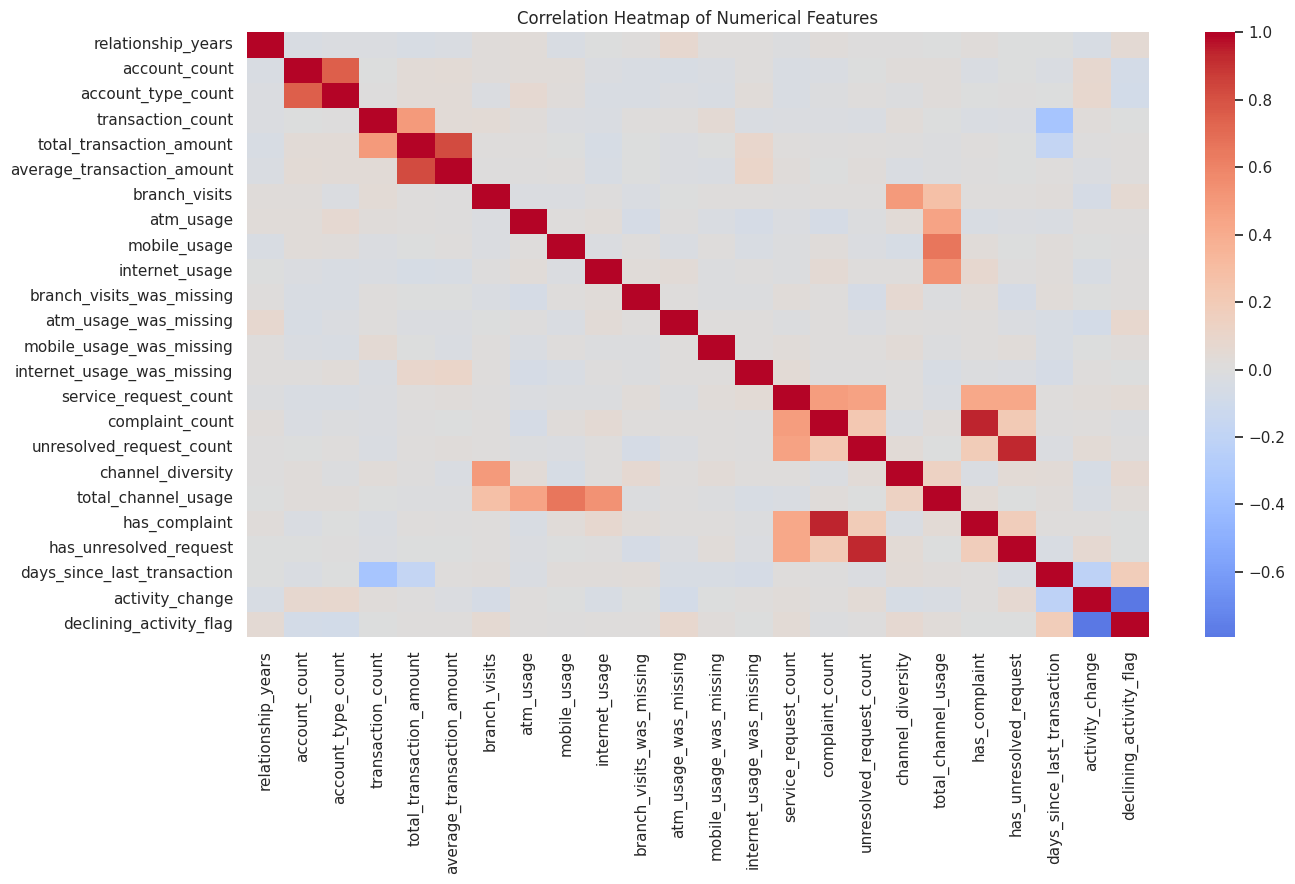

In [34]:
numeric_features = customer_data.select_dtypes(
    include=np.number
).drop(
    columns=["customer_id"],
    errors="ignore"
)

correlation_matrix = numeric_features.corr()

plt.figure(figsize=(14, 9))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# **Final checks and export your deliverables**

**Validate the cleaned dataset**

In [35]:
print("Final dataset shape:", customer_data.shape)

print("\nDuplicate customer IDs:",
      customer_data["customer_id"].duplicated().sum())

print("\nMissing values in final dataset:")
display(
    customer_data.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nEngagement segment distribution:")
display(
    customer_data["engagement_segment"]
    .value_counts()
    .to_frame("Customer Count")
)

Final dataset shape: (1200, 30)

Duplicate customer IDs: 0

Missing values in final dataset:


,Missing Count
customer_id,0
age_band,0
region,0
relationship_years,0
account_count,0
account_type_count,0
account_types,0
transaction_count,0
total_transaction_amount,0
average_transaction_amount,0



Engagement segment distribution:


,Customer Count
engagement_segment,
High,755
Moderate,410
Very High,28
Low,7


**Export cleaned data and features**

In [36]:
customer_data.to_csv(
    "trustwave_customer_cleaned.csv",
    index=False
)

accounts_clean.to_csv(
    "trustwave_accounts_cleaned.csv",
    index=False
)

transactions_clean.to_csv(
    "trustwave_transactions_cleaned.csv",
    index=False
)

channels_clean.to_csv(
    "trustwave_channels_cleaned.csv",
    index=False
)

service_clean.to_csv(
    "trustwave_service_cleaned.csv",
    index=False
)

feature_data.to_csv(
    "trustwave_selected_features.csv",
    index=False
)

encoded_data.to_csv(
    "trustwave_encoded_data.csv",
    index=False
)

print("All cleaned datasets and feature files exported successfully!")

All cleaned datasets and feature files exported successfully!
